# Anomaly Detection

Anomaly detection finds the **rare, unusual, suspicious** records in data — fraudulent transactions among millions of legitimate ones, a failing sensor in a factory stream, a mispriced listing, an unusual login. Unlike classification, you usually **don't have labels for anomalies** and don't even know how many to expect: this makes it a fundamentally *unsupervised* problem with an unusual evaluation story.

> **Prerequisites:** Level 2 Section 6 (clustering intuition), Level 3 Section 8 (Working with Outliers). That note covers *cleaning* outliers from training data; this note treats detection itself as **the task**.


## 1. Outliers, Anomalies, and Novelty — Three Related Problems

The literature uses three closely-related terms; keeping them straight avoids real confusion:

| Term | Setting | Question | Example |
|---|---|---|---|
| **Outlier handling** | Data cleaning (Level 3 §8) | Is this training-data point wrong/noisy? | Typos, broken sensors → fix or drop before modeling |
| **Anomaly detection** | Unsupervised, *in the same data* | Which points are far from everything else? | Flag suspicious transactions for review |
| **Novelty detection** | Semi-supervised, *clean training set* | Does this **new** point fit the known distribution? | New log-in pattern, new machine on a network |

Novelty detection is the most practical variant: you fit on data you *believe* is normal, then score each new observation as normal/novel. Everything below applies to both — scikit-learn exposes it via the `fit` on clean data + `predict` on new data pattern.


## 2. Why It Is Genuinely Hard

1. **No labels, unknown rate.** You rarely know what fraction of records is anomalous — yet the main hyperparameter (`contamination` in sklearn) *assumes* exactly that.
2. **Extreme imbalance.** Even with labels, anomalies are often < 1% of data, so accuracy is meaningless (predicting "all normal" scores 99.5%). Evaluation needs precision/recall on the *anomaly* class.
3. **Definition drifts.** "Normal" changes over time (spending patterns, seasonal load) — a detector that doesn't adapt goes stale; this is drift monitoring territory (Level 6).


## 3. Statistical Baselines and Where They Break

The Level 3 outlier notes use **z-scores** ($|z| > 3$) and **IQR fences**. These assume roughly unimodal, feature-by-feature data. They break when:

- the data is **multimodal** (a point can be perfectly normal for *each* feature yet sit in the empty region *between* modes — see the two-cluster experiment below);
- features are **correlated** (a value extreme only in the joint direction, like price-vs-area in housing);
- the anomaly is defined by a **combination** of ordinary values (fraud = ordinary amount, ordinary location, unusual *sequence*).

That is why real anomaly detection looks at the **joint density** — via trees, distances, or boundaries — rather than per-feature fences.


## 4. Isolation Forest — The Default Workhorse

**Idea** (Liu, Ting & Zhou, 2008): instead of modeling what normal looks like, *isolate* points. Randomly pick a feature, randomly pick a split value, recurse. Anomalies are **few and different**, so they get isolated in few random splits — short average path length = anomalous.

- Each tree is grown on a subsample; the anomaly score is the inverse of the mean path length (normalized).
- $O(n)$-ish, scales to large data, and makes **no density or distribution assumptions** — the reason it is the industry default (fraud, monitoring, log triage).
- Key hyperparameters: `contamination` (expected anomaly rate) and `n_estimators`/`max_samples`.

Comes with a built-in visualization intuition: anomalies separate from the dense regions.


## 5. Density, Distance, and Boundary Methods

| Method | Idea | Strength | Weakness |
|---|---|---|---|
| **Local Outlier Factor (LOF)** | Compare a point's local density ($k$-NN distance) with its neighbors' densities — low relative density = outlier | Catches anomalies *inside* sparse regions of a multi-cluster cloud; local notion of normal | Choice of $k$; transductive by default (use `novelty=True` to score new points) |
| **Elliptic Envelope** (Mahalanobis distance) | Fit a robust Gaussian, flag points far in joint covariance terms | Fast, principled for ~Gaussian data | Breaks beyond one elliptical mode |
| **One-Class SVM** | Learn a tight boundary (in kernel space) around the data; outside = anomaly | Flexible non-linear boundary | Sensitive to `gamma`/`nu`; scales poorly; needs careful tuning |
| **kNN distance** | Distance to $k$-th neighbor as a score | Simple, interpretable | No free lunch; cubic pairwise cost at scale |

> **PyOD** ([pyod.readthedocs.io](https://pyod.readthedocs.io/)) packages 40+ detectors (including all of the above plus deep autoencoder / GAN-based ones) behind one API — the reference library when you outgrow sklearn's four.


## 6. A Controlled Experiment

To *measure* detectors you need ground truth, so we build it: (a) a **2-D mixture of two Gaussian clusters** plus uniformly scattered points in between (a z-score per feature would happily call the gap points "normal on both axes"), and (b) the real **Wine dataset** (scikit-learn) with 15 samples corrupted by a strong shift — injected anomalies we know by construction. Precision/recall are computed against those known labels.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score

rng = np.random.RandomState(42)

# --- (a) two Gaussian modes + uniform anomalies in the empty middle ---
n_normal = 300
X_a = np.vstack([rng.normal([0, 0], 0.8, (n_normal, 2)),
                 rng.normal([5, 5], 0.9, (n_normal, 2))])
X_anom = rng.uniform(-4, 10, (25, 2))
X_2d = np.vstack([X_a, X_anom])
y_2d = np.hstack([np.zeros(2 * n_normal, int), np.ones(25, int)])
cont = 25 / len(X_2d)
print(f"2-D data: {len(X_2d)} points ({int(y_2d.sum())} true anomalies, contamination={cont:.3f})")

2-D data: 625 points (25 true anomalies, contamination=0.040)


In [2]:
# Same z-score idea per feature, for the point made in Section 3:
z = (X_2d - X_2d.mean(0)) / X_2d.std(0)
flagged_z = (np.abs(z).max(axis=1) > 3).astype(int)
print(f"z-score flags {flagged_z.sum()} of {int(y_2d.sum())} true anomalies "
      f"(P={precision_score(y_2d, flagged_z, zero_division=0):.2f}, "
      f"R={recall_score(y_2d, flagged_z):.2f})")

z-score flags 0 of 25 true anomalies (P=0.00, R=0.00)


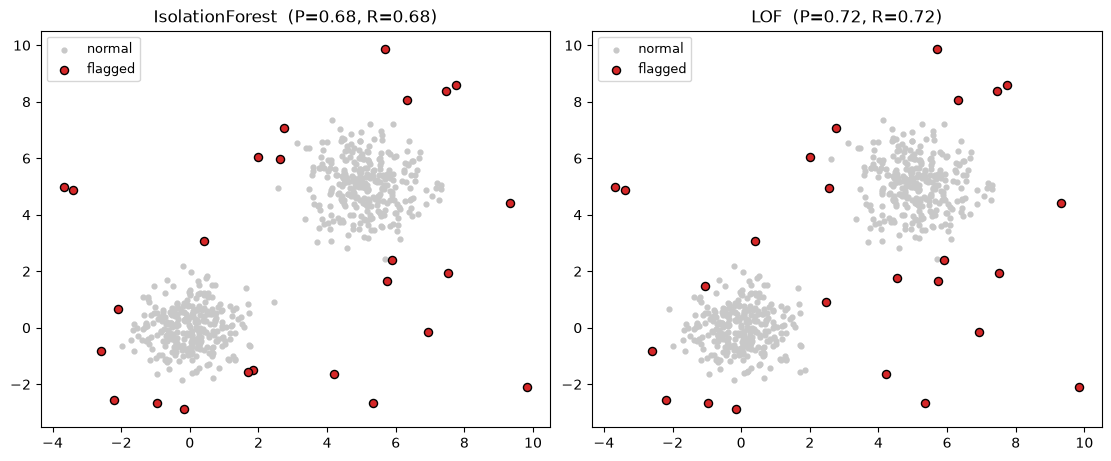

In [3]:
detectors = {
    "IsolationForest": IsolationForest(random_state=42, contamination=cont),
    "LOF": LocalOutlierFactor(n_neighbors=20, contamination=cont),
    "EllipticEnvelope": EllipticEnvelope(random_state=42, contamination=cont),
    "OneClassSVM": OneClassSVM(nu=cont, gamma="scale"),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, name in zip(axes, ["IsolationForest", "LOF"]):
    m = detectors[name]
    pred = (m.fit_predict(X_2d) == -1).astype(int)
    ax.scatter(X_2d[y_2d == 0, 0], X_2d[y_2d == 0, 1], s=12, color="#c8c8c8", label="normal")
    ax.scatter(X_2d[pred == 1, 0], X_2d[pred == 1, 1], s=34, color="#d62728",
               edgecolor="k", label="flagged")
    p, r = precision_score(y_2d, pred), recall_score(y_2d, pred)
    ax.set_title(f"{name}  (P={p:.2f}, R={r:.2f})")
    ax.legend(loc="upper left", fontsize=9)
plt.show()

In [4]:
# --- (b) real Wine data, 13 features, anomalies injected by strong shifts ---
from sklearn.base import clone

wine = load_wine()
X_w = StandardScaler().fit_transform(wine.data)
n_out = 15
idx = rng.choice(len(X_w), n_out, replace=False)
X_w[idx] += rng.uniform(3.5, 5.5, (n_out, X_w.shape[1]))
y_w = np.zeros(len(X_w), int); y_w[idx] = 1
cont_w = n_out / len(X_w)

rows = []
for name, m in detectors.items():
    m = clone(m)  # fresh copy: avoid reusing state from the 2-D experiment
    if isinstance(m, OneClassSVM):
        m.set_params(nu=cont_w)          # OneClassSVM uses nu, not contamination
    else:
        m.set_params(contamination=cont_w)
    pred = (m.fit_predict(X_w) == -1).astype(int)
    rows.append({"detector": name,
                 "precision": precision_score(y_w, pred),
                 "recall": recall_score(y_w, pred),
                 "flagged": int(pred.sum())})

pd.DataFrame(rows).round(2).sort_values("precision", ascending=False)

,detector,precision,recall,flagged
0,IsolationForest,1.00,1.0,15
1,LOF,1.00,1.0,15
2,EllipticEnvelope,1.00,1.0,15
3,OneClassSVM,0.43,0.4,14


Read these numbers with a straight face:

- On **easy, strongly-shifted** anomalies (Wine), Isolation Forest, LOF, and Elliptic Envelope are perfect — as expected; the injected shift is huge in 13 standardized dimensions.
- **One-Class SVM** lags at default hyperparameters: with `gamma='scale'` and `nu` set to the true rate, its boundary is too tight. It *can* be tuned into shape, but it is the honest example of a method that needs real care.
- On the **2-D gap experiment** both flagship detectors flag ~25 points as instructed by `contamination`, yet precision tops out around 0.7 — points from the *tails* of the two Gaussian modes land in the middle region too. With no labels, you would never know; this is exactly the "unknown rate" problem of Section 2.


## 7. Deep Anomaly Detection

When anomalies hide in structure that per-point distances miss — images, long sequences, graphs — **reconstruction-based** detectors dominate: train an autoencoder on presumed-normal data; anomalies reconstruct poorly, so **reconstruction error becomes the anomaly score**. The [Fundamentals of Neural Networks](https://github.com/AdilShamim8/ML-Roadmap-and-Notes/tree/main/4.%20Diving%20into%20different%20domains/Fundamentals%20of%20Neural%20Networks) note in this level builds the exact MLP machinery an autoencoder reuses (a bottlenecked architecture). Beyond autoencoders, the deep toolbox includes VAE likelihood, GAN discriminators, and sequence forecast error — again, PyOD wraps most of them.

> **Rule of thumb:** start with Isolation Forest; add LOF when data is multi-cluster; go deep only when data is perceptual/sequential and classical features fail.


## 8. Production Notes

- **The `contamination` guess controls your alert volume.** Too high → alert fatigue; too low → missed fraud. In production, tune the *score threshold* against review capacity (how many cases your analysts can actually check per day), not an abstract percentage.
- **Retrain or die.** Normal drifts (seasonality, growth, product changes). A novelty detector fit in January is wrong by July — schedule retraining and pair with drift monitoring (Level 6, Model Monitoring).
- **Feedback loop.** Analysts confirm or dismiss flagged cases; those labels are gold — log them and evaluate drift toward a *supervised* fraud model over time.
- **Streaming.** For high-throughput scoring, River and stream-aware variants update incrementally instead of refitting.


## Key Takeaways

- Anomaly detection = finding rare/unusual records **without labels**; novelty detection = the same machinery fit on clean data to score *new* arrivals.
- Per-feature z-scores/IQR break on multimodal or correlated data — model the **joint** distribution instead.
- **Isolation Forest** is the robust default (fast, assumption-free); **LOF** catches locally-sparse anomalies; **Elliptic Envelope** fits ~Gaussian data; **One-Class SVM** needs careful tuning.
- `contamination` is a *business decision* (alert volume), not a statistical constant — and with no labels, validate by injecting synthetic anomalies like we did above.
- **PyOD** is the one library to know beyond sklearn; autoencoder reconstruction error is the bridge to deep detection (NN Fundamentals note).
- Next in this roadmap: the **NLP** and **Time Series** notes complete Level 4, and Level 5's end-to-end project puts everything to work.
